In [200]:
## IMPORTING REQUIRED LIBRARIES /

In [201]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report


In [202]:
## LOADING DATASET

In [203]:
data = pd.read_csv("medication_adherence.csv")
data.head()


,patient_id,age,gender,chronic_condition,medication_type,dosage,comorbidities,BMI,event_id,timestamp,...,blood_pressure,blood_glucose,activity_level,sleep_hours,stress_level,reminder_sent,reminder_response_time,social_support,location,future_non_adherence
0,P0103,45,M,diabetes,Metformin,50,0,24.8,E00000,2025-05-22 02:46:32,...,139/81,170.2,8030,5.2,3,1,15.0,0,work,0
1,P0436,79,M,hypertension,Metformin,500,0,25.2,E00001,2025-03-02 22:26:25,...,123/82,80.1,5338,8.8,2,1,94.0,0,home,0
2,P0861,71,F,diabetes,Salbutamol,20,3,28.6,E00002,2025-09-13 02:37:54,...,138/80,110.1,9021,5.6,4,1,86.0,2,hospital,0
3,P0271,89,M,hypertension,Atorvastatin,10,0,22.9,E00003,2025-01-26 03:54:55,...,122/84,157.2,4930,4.8,4,1,100.0,4,hospital,0
4,P0107,84,F,diabetes,Amlodipine,10,3,34.5,E00004,2025-02-20 03:28:37,...,125/79,147.3,5960,7.6,3,0,NaN,2,hospital,0


In [204]:
## UNDERSTANDING THE DATA

In [205]:
data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2800 entries, 0 to 2799
Data columns (total 24 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   patient_id              2800 non-null   object 
 1   age                     2800 non-null   int64  
 2   gender                  2800 non-null   object 
 3   chronic_condition       2800 non-null   object 
 4   medication_type         2800 non-null   object 
 5   dosage                  2800 non-null   int64  
 6   comorbidities           2800 non-null   int64  
 7   BMI                     2800 non-null   float64
 8   event_id                2800 non-null   object 
 9   timestamp               2800 non-null   object 
 10  taken                   2800 non-null   int64  
 11  missed_reason           407 non-null    object 
 12  device_id               2800 non-null   object 
 13  heart_rate              2800 non-null   int64  
 14  blood_pressure          2800 non-null   

In [206]:
data.describe()


,age,dosage,comorbidities,BMI,taken,heart_rate,blood_glucose,activity_level,sleep_hours,stress_level,reminder_sent,reminder_response_time,social_support,future_non_adherence
count,2800.000000,2800.000000,2800.000000,2800.000000,2800.000000,2800.000000,2800.00000,2800.000000,2800.000000,2800.000000,2800.000000,1966.000000,2800.000000,2800.000000
mean,59.540357,109.005357,1.511786,26.469143,0.807500,79.454286,125.76225,5434.715357,6.492429,2.990357,0.702143,60.832655,2.476429,0.249286
std,17.215647,169.816542,1.126448,4.884759,0.394334,11.456180,31.71369,2599.331227,1.445301,1.394976,0.457398,33.500309,1.735908,0.432677
min,30.000000,5.000000,0.000000,18.000000,0.000000,60.000000,70.00000,1001.000000,4.000000,1.000000,0.000000,5.000000,0.000000,0.000000
25%,45.000000,10.000000,1.000000,22.300000,1.000000,70.000000,98.50000,3191.500000,5.300000,2.000000,0.000000,31.000000,1.000000,0.000000
50%,59.000000,35.000000,1.000000,26.500000,1.000000,79.000000,126.80000,5405.500000,6.500000,3.000000,1.000000,60.000000,2.000000,0.000000
75%,74.000000,100.000000,3.000000,30.625000,1.000000,90.000000,152.90000,7664.500000,7.700000,4.000000,1.000000,90.000000,4.000000,0.000000
max,89.000000,500.000000,3.000000,35.000000,1.000000,99.000000,180.00000,9999.000000,9.000000,5.000000,1.000000,119.000000,5.000000,1.000000


In [207]:
data.columns

Index(['patient_id', 'age', 'gender', 'chronic_condition', 'medication_type',
       'dosage', 'comorbidities', 'BMI', 'event_id', 'timestamp', 'taken',
       'missed_reason', 'device_id', 'heart_rate', 'blood_pressure',
       'blood_glucose', 'activity_level', 'sleep_hours', 'stress_level',
       'reminder_sent', 'reminder_response_time', 'social_support', 'location',
       'future_non_adherence'],
      dtype='object')

In [208]:
## DATA PREPROCESSING

In [209]:
data.ffill(inplace=True)


In [210]:
  ## USER MANAGEMENT

In [211]:
class User:
    def __init__(self, user_id, age, gender):
        self.user_id = user_id
        self.age = age
        self.gender = gender


In [212]:
## MEDICATION SCHEDULING MODULE

In [213]:
class Medication:
    def __init__(self, name, dosage, time, frequency):
        self.name = name
        self.dosage = dosage
        self.time = time
        self.frequency = frequency


In [214]:
## REMINDER ENGINE

In [215]:
def reminder_engine(reminder_sent):
    if reminder_sent == 1:
        return "Reminder Sent to Patient"
    else:
        return "Reminder Not Sent"


In [216]:
## MEDICATION INTAKE LOGGING

In [217]:
class IntakeLog:
    def __init__(self, taken):
        self.taken = taken  # 1 = taken, 0 = missed


In [218]:
## FEATURE SELECTION

In [219]:
gender_encoder = LabelEncoder()
medication_encoder = LabelEncoder()
condition_encoder = LabelEncoder()

data["gender_enc"] = gender_encoder.fit_transform(data["gender"])
data["medication_enc"] = medication_encoder.fit_transform(data["medication_type"])
data["condition_enc"] = condition_encoder.fit_transform(data["chronic_condition"])

In [220]:
# Features
X = data[
    [
        "age",
        "gender_enc",
        "medication_enc",
        "condition_enc",
        "dosage",
        "reminder_sent"
    ]
]

# Target
y = data["future_non_adherence"]



In [221]:
X["age"] = X["age"].astype(int)
X["dosage"] = X["dosage"].astype(float)
X["reminder_sent"] = X["reminder_sent"].astype(int)

C:\Users\pranitha ratna\AppData\Local\Temp\ipykernel_16168\1302371853.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X["age"] = X["age"].astype(int)
C:\Users\pranitha ratna\AppData\Local\Temp\ipykernel_16168\1302371853.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X["dosage"] = X["dosage"].astype(float)
C:\Users\pranitha ratna\AppData\Local\Temp\ipykernel_16168\1302371853.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,c

In [222]:
print(X.dtypes)

age                 int32
gender_enc          int32
medication_enc      int32
condition_enc       int32
dosage            float64
reminder_sent       int32
dtype: object


In [223]:
## TRAIN–TEST SPLIT

In [224]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [225]:
print(type(X_train))
print(X_train.shape)


<class 'pandas.core.frame.DataFrame'>
(2240, 6)


In [226]:
## FEATURE SCALING

In [227]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [228]:
## MACHINE LEARNING MODEL

In [229]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)



In [230]:
model.fit(X_train, y_train)


RandomForestClassifier(class_weight='balanced', random_state=42)

In [231]:
## MODEL EVALUATION

In [232]:
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Accuracy: 0.6767857142857143
              precision    recall  f1-score   support

           0       0.73      0.88      0.80       411
           1       0.25      0.11      0.15       149

    accuracy                           0.68       560
   macro avg       0.49      0.50      0.48       560
weighted avg       0.60      0.68      0.63       560



In [233]:
## SMART MEDICATION REMINDER LOGIC

In [234]:
def smart_reminder(prediction):
    if prediction == 1:
        return " High Risk: Patient may miss medication!"
    else:
        return " Low Risk: Patient likely to take medication"


In [235]:
sample = model.predict([X_test[0]])
print(smart_reminder(sample[0]))


 High Risk: Patient may miss medication!


In [236]:
## HEALTH ANALYTICS VISUALIZATION

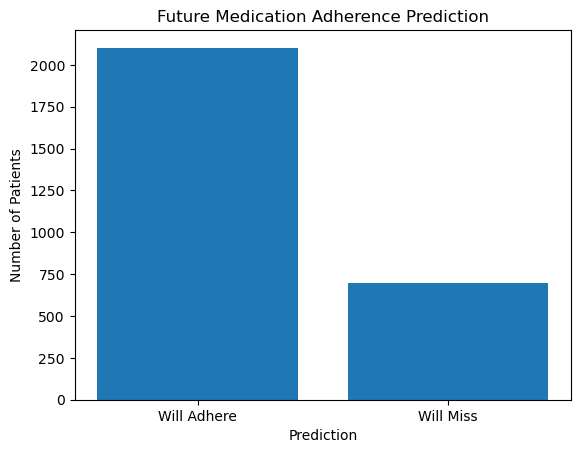

In [237]:
counts = data['future_non_adherence'].value_counts()

plt.bar(['Will Adhere', 'Will Miss'], counts)
plt.title("Future Medication Adherence Prediction")
plt.xlabel("Prediction")
plt.ylabel("Number of Patients")
plt.show()


In [238]:
import pickle
pickle.dump({
    "model": model,
    "scaler": scaler,
    "gender_encoder": gender_encoder,
    "medication_encoder": medication_encoder,
    "condition_encoder": condition_encoder
}, open("smr_model.pkl", "wb"))
